In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, utils
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, models, utils, callbacks, regularizers

df = pd.read_csv("/content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/merged_aqi_corrected_cleaned.csv")
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')

features = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']
target   = 'AQI_Category'


In [ ]:
# 1. Compute absolute counts and relative percentages
counts  = df['AQI_Category'].value_counts().sort_index()
percent = df['AQI_Category'].value_counts(normalize=True).mul(100).round(2).sort_index()

# 2. Combine into one DataFrame
freq_df = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percent
})

print(freq_df)


               Count  Percentage (%)
AQI_Category                        
Good           11800            4.35
Moderate      170940           63.00
Poor           14400            5.31
Satisfactory   37263           13.73
Severe          8842            3.26
Very Poor      28081           10.35


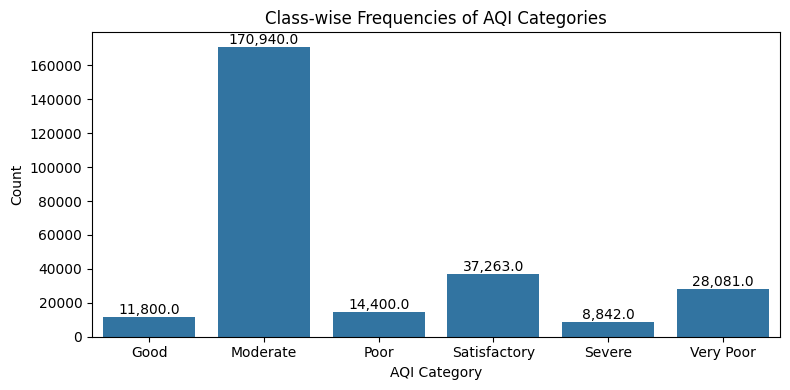

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,4))
sns.countplot(
    x='AQI_Category',
    data=df,
    order=freq_df.index
)
plt.title('Class-wise Frequencies of AQI Categories')
plt.xlabel('AQI Category')
plt.ylabel('Count')

# Annotate each bar with its height
for p in plt.gca().patches:
    plt.gca().annotate(
        f'{p.get_height():,}',
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha='center', va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()


In [ ]:
le = LabelEncoder()

df['AQI_Enc'] = le.fit_transform(df[target])

X = df[features].values
y = df['AQI_Enc'].values


# ============================================================
# STEP 3: Stratified 80/20 Train-Test Split
# BEFORE Normalization
# ============================================================

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ============================================================
# STEP 4: Separate Validation Dataset
# 15% of the 80% training portion
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.15,
    random_state=42,
    stratify=y_train_full
)


# ============================================================
# STEP 5: Normalize Features Without Data Leakage
# ============================================================

scaler = MinMaxScaler()

# Fit only on actual training data
X_train = scaler.fit_transform(X_train)

# Transform validation data
X_val = scaler.transform(X_val)

# Transform testing data
X_test = scaler.transform(X_test)


# ============================================================
# STEP 6: Confirm Class-Wise Distribution
# ============================================================

orig_counts = pd.Series(
    le.inverse_transform(y)
).value_counts().sort_index()

train_counts = pd.Series(
    le.inverse_transform(y_train)
).value_counts().sort_index()

val_counts = pd.Series(
    le.inverse_transform(y_val)
).value_counts().sort_index()

test_counts = pd.Series(
    le.inverse_transform(y_test)
).value_counts().sort_index()

split_df = pd.DataFrame({
    'Total': orig_counts,
    'Train': train_counts,
    'Validation': val_counts,
    'Test': test_counts
}).fillna(0).astype(int)

split_df['Train %'] = (
    split_df['Train'] / split_df['Total'] * 100
).round(2)

split_df['Validation %'] = (
    split_df['Validation'] / split_df['Total'] * 100
).round(2)

split_df['Test %'] = (
    split_df['Test'] / split_df['Total'] * 100
).round(2)

print("\n=== Class-Wise Dataset Distribution ===")
print(split_df)

print("\nTraining shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)


=== Class-Wise Dataset Distribution ===
               Total   Train  Validation   Test  Train %  Validation %  Test %
Good           11800    8024        1416   2360     68.0          12.0    20.0
Moderate      170940  116238       20513  34189     68.0          12.0    20.0
Poor           14400    9792        1728   2880     68.0          12.0    20.0
Satisfactory   37263   25339        4471   7453     68.0          12.0    20.0
Severe          8842    6013        1061   1768     68.0          12.0    20.0
Very Poor      28081   19095        3370   5616     68.0          12.0    20.0

Training shape: (184501, 6)
Validation shape: (32559, 6)
Testing shape: (54266, 6)


In [ ]:
import time

num_classes = len(le.classes_)

y_train_cat = utils.to_categorical(
    y_train,
    num_classes
)

y_val_cat = utils.to_categorical(
    y_val,
    num_classes
)

y_test_cat = utils.to_categorical(
    y_test,
    num_classes
)


# ============================================================
# STEP 7: Build Residual DNN Model
# Original Architecture Preserved
# ============================================================

inputs = tf.keras.Input(
    shape=(len(features),)
)

# First Dense + Batch Normalization + Dropout
x = layers.Dense(
    128,
    activation='relu',
    kernel_regularizer=regularizers.l2(1e-4)
)(inputs)

x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)


# Residual Block
res = x

x = layers.Dense(
    128,
    activation='relu',
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

x = layers.BatchNormalization()(x)
x = layers.Add()([x, res])
x = layers.Dropout(0.4)(x)


# Deeper Dense Layers
x = layers.Dense(
    64,
    activation='relu',
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(
    32,
    activation='relu',
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)


# Output Layer
outputs = layers.Dense(
    num_classes,
    activation='softmax'
)(x)


# ============================================================
# STEP 8: Compile Model
# ============================================================

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


# ============================================================
# STEP 9: Callbacks
# ============================================================

es = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

rlr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3
)


# ============================================================
# STEP 10: Train DNN Model
# ============================================================

start_time = time.perf_counter()

history = model.fit(
    X_train,
    y_train_cat,

    validation_data=(
        X_val,
        y_val_cat
    ),

    epochs=100,
    batch_size=32,
    callbacks=[es, rlr],
    verbose=2
)

training_time = time.perf_counter() - start_time

print(
    f"\nTraining Time: {training_time:.2f} seconds"
)


# ============================================================
# STEP 11: Final Evaluation
# ============================================================

# Training accuracy (inference mode)
train_loss, train_acc = model.evaluate(
    X_train,
    y_train_cat,
    verbose=0
)

# Validation accuracy
val_loss, val_acc = model.evaluate(
    X_val,
    y_val_cat,
    verbose=0
)

# Testing accuracy
test_loss, test_acc = model.evaluate(
    X_test,
    y_test_cat,
    verbose=0
)

print("\n=== Final DNN Accuracy ===")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │        896 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128)       │        512 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     16,512 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128)       │          0 │ batch_normalizat… │
│                     │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 6)         │        198 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 29,350 (114.65 KB)

 Trainable params: 28,646 (111.90 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/100
5766/5766 - 25s - 4ms/step - accuracy: 0.8512 - loss: 0.4087 - val_accuracy: 0.9486 - val_loss: 0.1553 - learning_rate: 0.0010
Epoch 2/100
5766/5766 - 23s - 4ms/step - accuracy: 0.9134 - loss: 0.2506 - val_accuracy: 0.9627 - val_loss: 0.1270 - learning_rate: 0.0010
Epoch 3/100
5766/5766 - 23s - 4ms/step - accuracy: 0.9279 - loss: 0.2174 - val_accuracy: 0.9603 - val_loss: 0.1245 - learning_rate: 0.0010
Epoch 4/100
5766/5766 - 23s - 4ms/step - accuracy: 0.9320 - loss: 0.2044 - val_accuracy: 0.9686 - val_loss: 0.1075 - learning_rate: 0.0010
Epoch 5/100
5766/5766 - 22s - 4ms/step - accuracy: 0.9353 - loss: 0.1961 - val_accuracy: 0.9673 - val_loss: 0.1108 - learning_rate: 0.0010
Epoch 6/100
5766/5766 - 22s - 4ms/step - accuracy: 0.9380 - loss: 0.1897 - val_accuracy: 0.9638 - val_loss: 0.1167 - learning_rate: 0.0010
Epoch 7/100
5766/5766 - 22s - 4ms/step - accuracy: 0.9393 - loss: 0.1860 - val_accuracy: 0.9635 - val_loss: 0.1134 - learning_rate: 0.0010
Epoch 8/100
5766/5766 - 22s

=== DNN Accuracy ===
Training Accuracy: 0.988802
Test Accuracy: 0.988133

=== DNN CLASS-WISE AP ===
Model Dataset AQI Category  Support  Average Precision
  DNN   Merge         Good     2360           0.982425
  DNN   Merge     Moderate    34189           0.999939
  DNN   Merge         Poor     2880           0.996738
  DNN   Merge Satisfactory     7453           0.995656
  DNN   Merge       Severe     1768           0.999955
  DNN   Merge    Very Poor     5616           0.999779

=== DNN OVERALL AP ===
Macro AP    : 0.995749
Weighted AP : 0.998403
Micro AP    : 0.999360

=== DNN PERFORMANCE SUMMARY ===
Model Dataset  Train Accuracy  Test Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted Precision  Weighted Recall  Weighted F1  Macro AP  Weighted AP  Micro AP  Inference Time (s)
  DNN   Merge        0.988802       0.988133         0.972791      0.980113  0.976378            0.988283         0.988133     0.988182  0.995749     0.998403   0.99936            3.114391

=== DNN CL

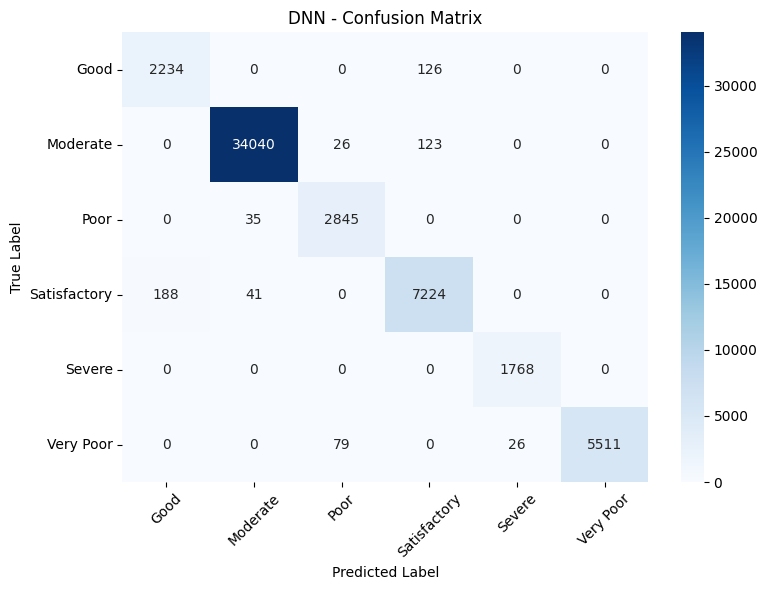

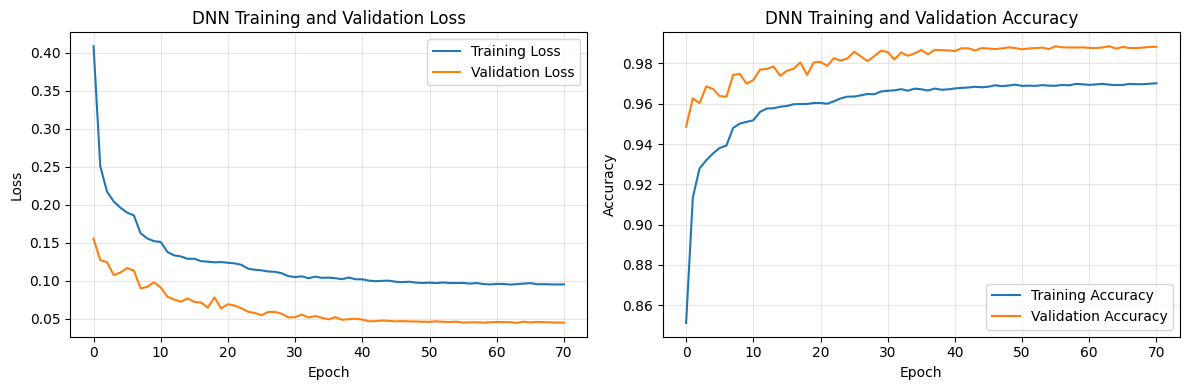


=== ALL DNN RESULTS SAVED ===
Directory: /content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New
Saved: /content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/DNN_Overall_Results_AP.csv
Saved: /content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/DNN_Classwise_AP.csv
Saved: /content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/DNN_Classification_Report.csv
Saved: /content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/DNN_Confusion_Matrix.csv
Saved: /content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/DNN_Confusion_Matrix.png
Saved: /content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/DNN_Training_Curves.png


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    average_precision_score
)

# ============================================================
# SAVE DIRECTORY
# ============================================================

SAVE_DIR = Path(
    "/content/drive/MyDrive/My work/"
    "Air Quality Project/Paper 1(External Data)/New/"
)

# Make sure Google Drive is mounted in Colab
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 12: FINAL EVALUATION
# ============================================================

train_loss, train_acc = model.evaluate(
    X_train, y_train_cat, verbose=0
)

test_loss, test_acc = model.evaluate(
    X_test, y_test_cat, verbose=0
)

print("=== DNN Accuracy ===")
print(f"Training Accuracy: {train_acc:.6f}")
print(f"Test Accuracy: {test_acc:.6f}")

# ============================================================
#13: PREDICTIONS AND INFERENCE TIME
# ============================================================

start_time = time.perf_counter()

y_pred_prob = model.predict(
    X_test,
    verbose=0
)

inference_time = time.perf_counter() - start_time

y_pred = np.argmax(y_pred_prob, axis=1)

# ============================================================
# 14: PERFORMANCE METRICS
# ============================================================

acc = accuracy_score(y_test, y_pred)

macro_precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

weighted_precision = precision_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

weighted_recall = recall_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

weighted_f1 = f1_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

# ============================================================
# 15: MULTICLASS AVERAGE PRECISION (AP)
# ============================================================

# One-hot encoded true labels
y_true_onehot = np.asarray(y_test_cat)

# Predicted class probabilities
y_prob = np.asarray(y_pred_prob)

class_names = [str(c) for c in le.classes_]
class_labels = np.arange(len(class_names))

# Check consistency
assert y_true_onehot.shape == y_prob.shape, (
    "One-hot labels and probabilities must have "
    "the same shape."
)

assert y_prob.shape[1] == len(class_names), (
    "Number of output probabilities must match "
    "the number of AQI categories."
)

assert np.array_equal(
    np.argmax(y_true_onehot, axis=1),
    np.asarray(y_test).reshape(-1)
), "The one-hot labels do not match y_test."

# ------------------------------------------------------------
# Overall Average Precision
# ------------------------------------------------------------

macro_ap = average_precision_score(
    y_true_onehot,
    y_prob,
    average="macro"
)

weighted_ap = average_precision_score(
    y_true_onehot,
    y_prob,
    average="weighted"
)

micro_ap = average_precision_score(
    y_true_onehot,
    y_prob,
    average="micro"
)

# ------------------------------------------------------------
# Class-wise Average Precision
# ------------------------------------------------------------

classwise_ap_results = []

for i, class_name in enumerate(class_names):

    class_ap = average_precision_score(
        y_true_onehot[:, i],
        y_prob[:, i]
    )

    classwise_ap_results.append({
        "Model": "DNN",
        "Dataset": "Merge",
        "AQI Category": class_name,
        "Support": int(y_true_onehot[:, i].sum()),
        "Average Precision": class_ap
    })

classwise_ap_df = pd.DataFrame(
    classwise_ap_results
)

print("\n=== DNN CLASS-WISE AP ===")

print(
    classwise_ap_df.round(6).to_string(
        index=False
    )
)

print("\n=== DNN OVERALL AP ===")
print(f"Macro AP    : {macro_ap:.6f}")
print(f"Weighted AP : {weighted_ap:.6f}")
print(f"Micro AP    : {micro_ap:.6f}")

# ============================================================
# 16: RESULTS SUMMARY
# ============================================================

results_df = pd.DataFrame([{
    "Model": "DNN",
    "Dataset": "Merge",
    "Train Accuracy": train_acc,
    "Test Accuracy": acc,
    "Macro Precision": macro_precision,
    "Macro Recall": macro_recall,
    "Macro F1": macro_f1,
    "Weighted Precision": weighted_precision,
    "Weighted Recall": weighted_recall,
    "Weighted F1": weighted_f1,
    "Macro AP": macro_ap,
    "Weighted AP": weighted_ap,
    "Micro AP": micro_ap,
    "Inference Time (s)": inference_time
}])

print("\n=== DNN PERFORMANCE SUMMARY ===")

print(
    results_df.round(6).to_string(
        index=False
    )
)

# ============================================================
# 17: CLASSIFICATION REPORT
# ============================================================

report_text = classification_report(
    y_test,
    y_pred,
    labels=class_labels,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\n=== DNN CLASSIFICATION REPORT ===")
print(report_text)

report_dict = classification_report(
    y_test,
    y_pred,
    labels=class_labels,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).T

# ============================================================
# 18: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("DNN - Confusion Matrix")

plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    SAVE_DIR / "DNN_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 19: TRAINING CURVES
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(12, 4)
)

# Loss
ax1.plot(
    history.history["loss"],
    label="Training Loss"
)

ax1.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

ax1.set_title("DNN Training and Validation Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(alpha=0.3)

# Accuracy
ax2.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

ax2.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

ax2.set_title("DNN Training and Validation Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    SAVE_DIR / "DNN_Training_Curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 20: SAVE ALL RESULTS TO GOOGLE DRIVE
# ============================================================

# Overall metrics
results_df.to_csv(
    SAVE_DIR / "DNN_Overall_Results_AP.csv",
    index=False
)

# Class-wise AP
classwise_ap_df.to_csv(
    SAVE_DIR / "DNN_Classwise_AP.csv",
    index=False
)

# Precision, Recall, F1 and Support
report_df.to_csv(
    SAVE_DIR / "DNN_Classification_Report.csv"
)

# Confusion matrix values
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    SAVE_DIR / "DNN_Confusion_Matrix.csv"
)

print("\n=== ALL DNN RESULTS SAVED ===")
print("Directory:", SAVE_DIR)

for filename in [
    "DNN_Overall_Results_AP.csv",
    "DNN_Classwise_AP.csv",
    "DNN_Classification_Report.csv",
    "DNN_Confusion_Matrix.csv",
    "DNN_Confusion_Matrix.png",
    "DNN_Training_Curves.png"
]:
    print("Saved:", SAVE_DIR / filename)


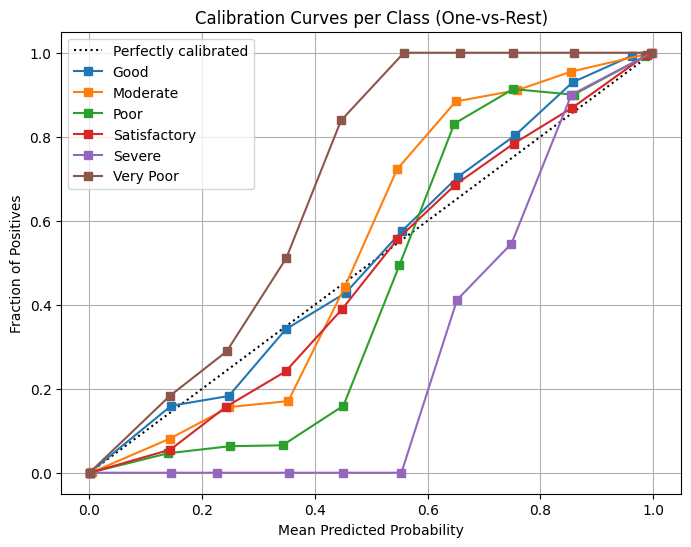

In [ ]:
from sklearn.calibration import CalibrationDisplay
from sklearn.preprocessing import label_binarize



# Define y_test_bin by one-hot encoding y_test
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(le.classes_):
    CalibrationDisplay.from_predictions(
        y_test_bin[:, i],
        y_pred_prob[:, i], # Corrected variable name to y_pred_prob
        n_bins=10,
        name=f'{class_name}',
        ax=plt.gca() # Plot all curves on the same axes
    )

plt.title('Calibration Curves per Class (One-vs-Rest)')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

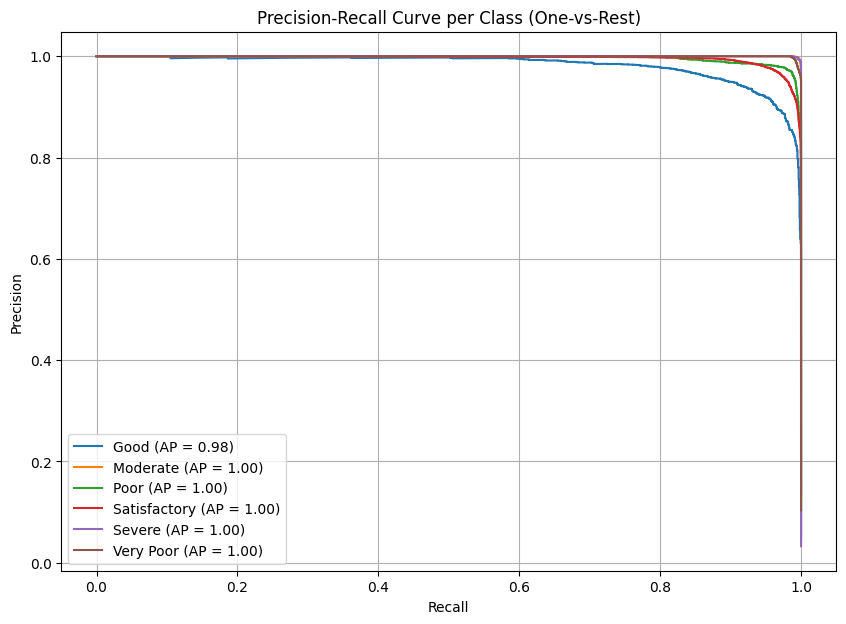

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

for i, class_name in enumerate(le.classes_):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_pred_prob[:, i])
    ap_score = average_precision_score(y_test_bin[:, i], y_pred_prob[:, i])
    plt.plot(recall, precision, label=f'{class_name} (AP = {ap_score:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve per Class (One-vs-Rest)')
plt.legend()
plt.grid(True)
plt.show()